In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
region_movements = {
    1: (0, -1),
    2: (-1, 0),
    3: (0, 1),
    4: (1, 0),
}

In [11]:
def generate_values(margin):
    # Randomly generate a value in the range (0, 0.12)
    value1 = np.random.uniform(0, 0.12)

    # The remaining sum needed to complete the total to 1
    remaining_sum = 1 - value1

    # Randomly generate three values that sum to remaining_sum
    values = np.random.rand(3)
    values /= values.sum()  # Normalize to sum to 1
    values *= remaining_sum  # Scale to the remaining_sum

    # Combine the fixed value with the generated values
    all_values = np.concatenate(([value1], values))

    # Ensure that the first value is less than 0.12
    # Randomize the Rest
    # But if the third value is within margin value of the first value, then we do not use the distribution

    # Ensure the first and third are not similar, and the second and fourth are not similar
    while abs(all_values[0] - all_values[2]) < margin:# or abs(all_values[1] - all_values[3]) < 0.1: not needed
        value1 = np.random.uniform(0, 0.12)
        remaining_sum = 1 - value1
        values = np.random.rand(3)
        values /= values.sum()
        values *= remaining_sum
        all_values = np.concatenate(([value1], values))

    # Initialize a new 4x4 array
    result_array = np.zeros((4, 4))

    # Fill the new array with shifted versions of the original array
    for i in range(4):
        result_array[i] = np.roll(all_values, shift=i)

    return result_array

In [12]:
def measure_uniformity(hist):
    # Calculate the variance of bin counts
    mean_count = np.mean(hist)
    std_dev = np.std(hist)

    # Compute the Coefficient of Variation (CV)
    if mean_count == 0:
        cv = np.inf  # Handle division by zero if mean_count is zero
    else:
        cv = std_dev / mean_count

    # Normalize the uniformity score to range [0, 1]
    # Inverting CV and scaling to [0, 1] range
    uniformity_score = 1 / (1 + cv)  # Smaller CV means higher uniformity
    return uniformity_score

In [13]:
def fitness_function(x, y, num_agents, total_bins):
    # Convert inputs to numpy arrays for convenience
    x = np.array(x)
    y = np.array(y)

    # Compute Manhattan distances from origin
    distances = np.abs(x) + np.abs(y)

    # Criteria 1: Few points near the origin
    # Points are considered near origin if their Manhattan distance is <= num_agents/3
    near_origin_count = np.sum(distances <= num_agents / 5)
    total_points = len(distances)

    # Fitness for avoiding origin
    fitness_origin_avoidance = 1 - (near_origin_count / total_points)

    # Criteria 2: Spread out the points
    # Compute the angle of each point from the origin
    angles = np.arctan2(y, x) * (180 / np.pi)  # Convert radians to degrees
    angles = (angles + 360) % 360  # Normalize angles to range [0, 360)

    # Define bin edges for *total_bins* bins, each representing 6 degrees
    bin_edges = np.linspace(0, 360, total_bins + 1)  # total_bins + 1 edges for total_bins bins

    # Calculate histogram of angles
    hist, _ = np.histogram(angles, bins=bin_edges)

    density = measure_uniformity(hist)

    return fitness_origin_avoidance, density

In [14]:
def run_test(num_p_arrays, num_agents, margin, num_simulations):
    combined_p_arrays = np.zeros((0, 4))
    for i in range(num_p_arrays):
        p_arrays_temp = generate_values(margin)
        combined_p_arrays = np.vstack((combined_p_arrays, p_arrays_temp))
    num_distributions = combined_p_arrays.shape[0]
    cumulative_x_movement = np.zeros(num_simulations)
    cumulative_y_movement = np.zeros(num_simulations)

    # Perform simulations
    for i in range(num_simulations):
        # Generate random region selections based on probabilities
        p = combined_p_arrays[i % num_distributions]
        agent_regions = np.random.choice(list(region_movements.keys()), size=num_agents, p=p) #100 s

        # Calculate net movements in x and y directions
        total_x_movement = sum(region_movements[region][0] for region in agent_regions)
        total_y_movement = sum(region_movements[region][1] for region in agent_regions)

        # Store cumulative movements
        cumulative_x_movement[i] = total_x_movement
        cumulative_y_movement[i] = total_y_movement
    return fitness_function(cumulative_x_movement, cumulative_y_movement, num_agents, 60)

In [15]:
def find_min_p_array(num_agents, margin_values, num_tests, num_simulations):
    # Given parameters
    graph_x = []
    graph_y1 = []
    graph_y2 = []
    num_p_array = 100

    while num_p_array < num_tests + 1:
      _, y1 = run_test(num_p_array, num_agents, margin_values[0], num_simulations)
      _, y2 = run_test(num_p_array, num_agents, margin_values[1], num_simulations)
      graph_y1.append(y1)
      graph_y2.append(y2)
      graph_x.append(num_p_array)
      print(num_p_array, end="")
      num_p_array += 5
    return graph_x, graph_y1, graph_y2

100105110115120125130135140145150

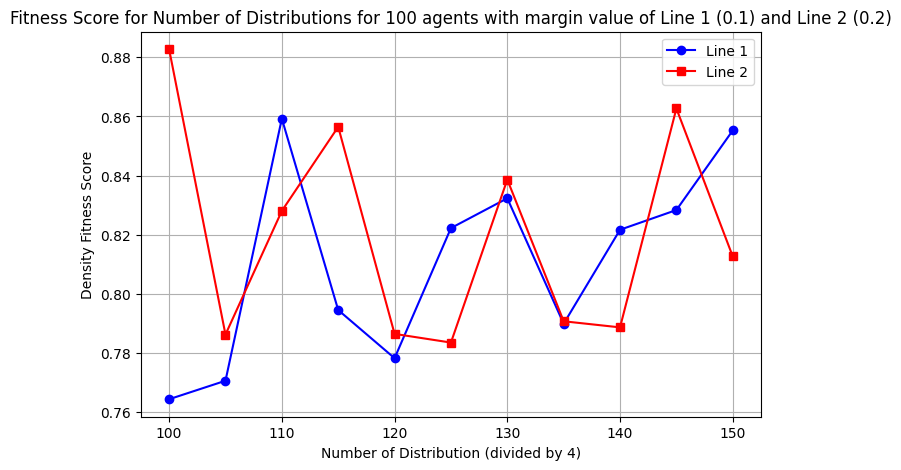

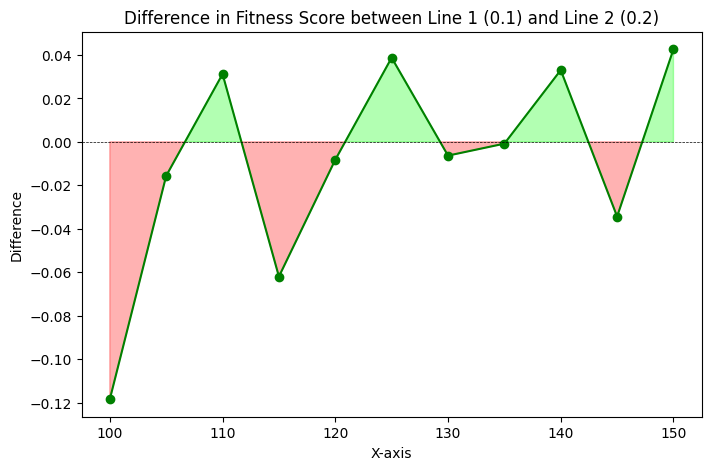

In [16]:
# Assuming find_min_p_array() returns x, y1, y2
num_agent = 100
num_tests = 150
num_simulations = 4000
margin_values = [0.1, 0.2]
x, y1, y2 = find_min_p_array(num_agent, margin_values, num_tests, num_simulations)

plt.figure(figsize=(8, 5))
plt.plot(x, y1, marker='o', linestyle='-', color='b', label='Line 1')
plt.plot(x, y2, marker='s', linestyle='-', color='r', label='Line 2')
plt.xlabel('Number of Distribution (divided by 4)')
plt.ylabel('Density Fitness Score')
plt.title(f'Fitness Score for Number of Distributions for {num_agent} agents with margin value of Line 1 ({margin_values[0]}) and Line 2 ({margin_values[1]})')
plt.legend()
plt.grid(True)
plt.show()
plt.figure(figsize=(8, 5))

y_diff = np.array(y1) - np.array(y2)

plt.plot(x, y_diff, marker='o', linestyle='-', color='g', label='Difference')
plt.fill_between(x, y_diff, where=(y_diff >= 0), interpolate=True, color='lime', alpha=0.3)
plt.fill_between(x, y_diff, where=(y_diff < 0), interpolate=True, color='red', alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
plt.xlabel('X-axis')
plt.ylabel('Difference')
plt.title(f'Difference in Fitness Score between Line 1 ({margin_values[0]}) and Line 2 ({margin_values[1]})')
plt.show()